In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

In [2]:
(x_train, y_train), (x_test, y_test) = (
    (np.fromfile('MNIST/train-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/train-labels-idx1-ubyte', np.uint8)[8:]),
    (np.fromfile('MNIST/t10k-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/t10k-labels-idx1-ubyte', np.uint8)[8:])
)

x_train = x_train.reshape(-1, 784).astype('float32') / 255.0
x_test = x_test.reshape(-1, 784).astype('float32') / 255.0

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

Training Data: (60000, 784)
Testing Data: (10000, 784)


In [3]:
activations = ['sigmoid', 'tanh', 'relu']
results = {}

In [4]:
for act in activations:

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(784,)),
        tf.keras.layers.Dense(128, activation=act),
        tf.keras.layers.Dense(64, activation=act),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    start = time.time()

    history = model.fit(
        x_train, y_train,
        epochs=5,
        batch_size=128,
        validation_split=0.2,
        verbose=1
    )

    training_time = time.time() - start

    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    results[act] = {
        'model': model,
        'history': history.history,
        'time': training_time,
        'accuracy': accuracy
    }

    print(act, "Accuracy:", accuracy * 100)
    print("Training Time:", training_time)

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.7875 - loss: 0.9175 - val_accuracy: 0.9097 - val_loss: 0.3606
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9160 - loss: 0.3087 - val_accuracy: 0.9316 - val_loss: 0.2475
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9347 - loss: 0.2306 - val_accuracy: 0.9425 - val_loss: 0.2054
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9455 - loss: 0.1877 - val_accuracy: 0.9520 - val_loss: 0.1736
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9537 - loss: 0.1577 - val_accuracy: 0.9556 - val_loss: 0.1561
sigmoid Accuracy: 95.59000134468079
Training Time: 23.92119598388672
Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8914 - loss: 0.3801 - val_accuracy: 0.9368 - val_loss: 0.2236
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9455 - loss: 0.1853 - val_accuracy: 0.9517 - val_loss: 0.1632
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 3

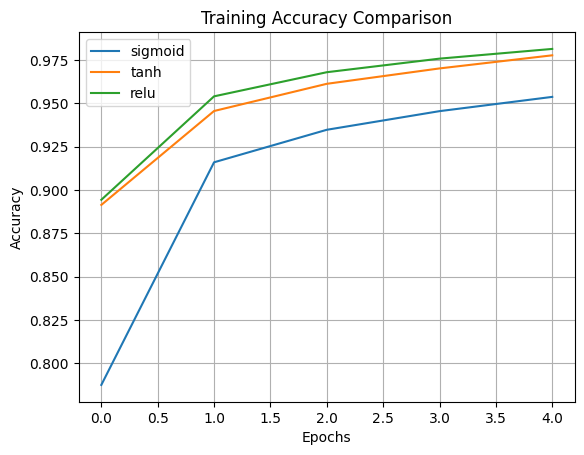

In [5]:
for act in activations:
    plt.plot(results[act]['history']['accuracy'], label=act)

plt.title("Training Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

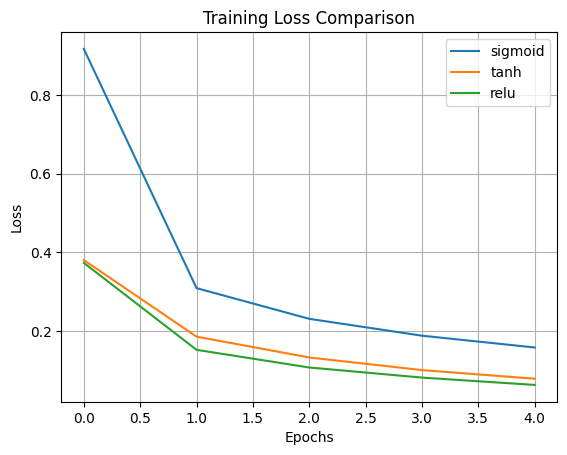

In [6]:
for act in activations:
    plt.plot(results[act]['history']['loss'], label=act)

plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

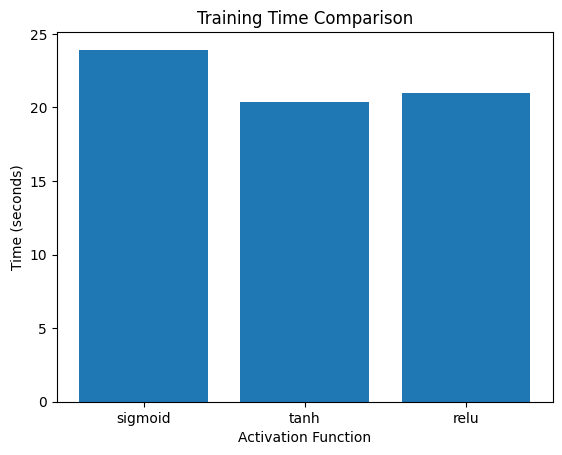

In [7]:
plt.bar(activations, [results[a]['time'] for a in activations])

plt.title("Training Time Comparison")
plt.xlabel("Activation Function")
plt.ylabel("Time (seconds)")
plt.show()

In [8]:
x = tf.convert_to_tensor(x_train[:128], dtype=tf.float32)
y = tf.convert_to_tensor(y_train[:128], dtype=tf.int64)

gradient_values = {}

for act in activations:

    model = results[act]['model']

    with tf.GradientTape() as tape:
        predictions = model(x, training=True)

        loss = tf.keras.losses.sparse_categorical_crossentropy(
            y, predictions
        )
        loss = tf.reduce_mean(loss)

    gradients = tape.gradient(loss, model.trainable_variables)

    gradient_values[act] = [
        tf.reduce_mean(tf.abs(g)).numpy()
        for g in gradients if g is not None
    ]

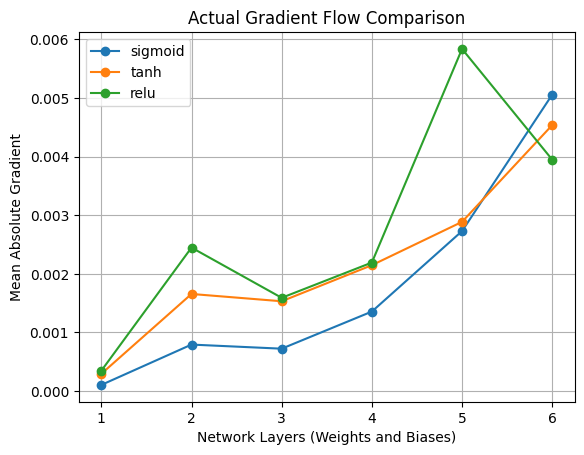

In [9]:
for act in activations:
    plt.plot(
        range(1, len(gradient_values[act]) + 1),
        gradient_values[act],
        marker='o',
        label=act
    )

plt.title("Actual Gradient Flow Comparison")
plt.xlabel("Network Layers (Weights and Biases)")
plt.ylabel("Mean Absolute Gradient")
plt.legend()
plt.grid()
plt.show()

In [10]:
print("\nFINAL COMPARISON")

for act in activations:
    print("\nActivation:", act)
    print("Accuracy:", results[act]['accuracy'] * 100, "%")
    print("Training Time:", results[act]['time'], "seconds")
    print("Gradient Values:", gradient_values[act])


FINAL COMPARISON

Activation: sigmoid
Accuracy: 95.59000134468079 %
Training Time: 23.92119598388672 seconds
Gradient Values: [np.float32(0.000106116095), np.float32(0.00079392584), np.float32(0.0007239734), np.float32(0.0013569221), np.float32(0.0027290718), np.float32(0.005055974)]

Activation: tanh
Accuracy: 97.00000286102295 %
Training Time: 20.35509753227234 seconds
Gradient Values: [np.float32(0.0002952685), np.float32(0.0016569863), np.float32(0.0015326096), np.float32(0.0021474739), np.float32(0.0028863547), np.float32(0.0045365132)]

Activation: relu
Accuracy: 97.10999727249146 %
Training Time: 20.984761953353882 seconds
Gradient Values: [np.float32(0.00034805955), np.float32(0.002447611), np.float32(0.0015913472), np.float32(0.002192495), np.float32(0.00583501), np.float32(0.0039458247)]
